In [2]:
# Load the data

from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("codex_closure_data")  # change if needed

pointer = json.loads((ROOT / "latest_run.json").read_text())
RUN = ROOT / "runs" / pointer["run_id"]
manifest = json.loads((RUN / "manifest.json").read_text())

if not manifest["complete_for_query_scope"]:
    raise ValueError("Collection is incomplete. Resume it before plotting.")

START = pd.Timestamp(manifest["start"])
END = pd.Timestamp(manifest["end_exclusive"])

closures = pd.read_csv(RUN / "records.csv")
closures["event_at"] = pd.to_datetime(closures["event_at"], utc=True)

closures = closures[
    (closures["event_at"] >= START)
    & (closures["event_at"] < END)
].drop_duplicates(["activity_type", "id"])

events = closures.copy()

In [3]:
# Create weekly and monthly counts

LABELS = {
    "commits": "Commits",
    "opened_prs": "PRs opened",
    "merged_prs": "PRs merged",
    "closed_without_merge_prs": "PRs closed without merge",
    "opened_issues": "Issues opened",
    "closed_issues": "Issues closed",
}

def make_counts(events, frequency):
    # Convert UTC timestamps to timezone-naive values for calendar grouping.
    times = events["event_at"].dt.tz_convert("UTC").dt.tz_localize(None)
    start = START.tz_convert("UTC").tz_localize(None)
    end = END.tz_convert("UTC").tz_localize(None)

    # W-SUN means Monday–Sunday weeks.
    rule = {"weekly": "W-SUN", "monthly": "M"}[frequency]

    periods = pd.period_range(
        start=start.to_period(rule),
        end=(end - pd.Timedelta(nanoseconds=1)).to_period(rule),
        freq=rule,
    )

    data = events.assign(period=times.dt.to_period(rule))

    counts = (
        data.groupby(["period", "activity_type"])
        .size()
        .unstack(fill_value=0)
        .reindex(periods, fill_value=0)
    )

    counts.index = periods.start_time
    counts.index.name = "period_start"

    partial = pd.Series(
        (periods.start_time < start)
        | ((periods + 1).start_time > end),
        index=counts.index,
    )

    return counts, partial

weekly, weekly_partial = make_counts(events, "weekly")
monthly, monthly_partial = make_counts(events, "monthly")

# display(weekly)
display(monthly)

activity_type,closed_issues,closed_without_merge_prs,merged_prs
period_start,,,
2025-10-01,247,275,142
2025-11-01,962,319,382
2025-12-01,529,190,427
2026-01-01,739,291,644
2026-02-01,888,438,892
2026-03-01,1047,415,861
2026-04-01,1200,545,1098
2026-05-01,1216,649,959
2026-06-01,849,793,950


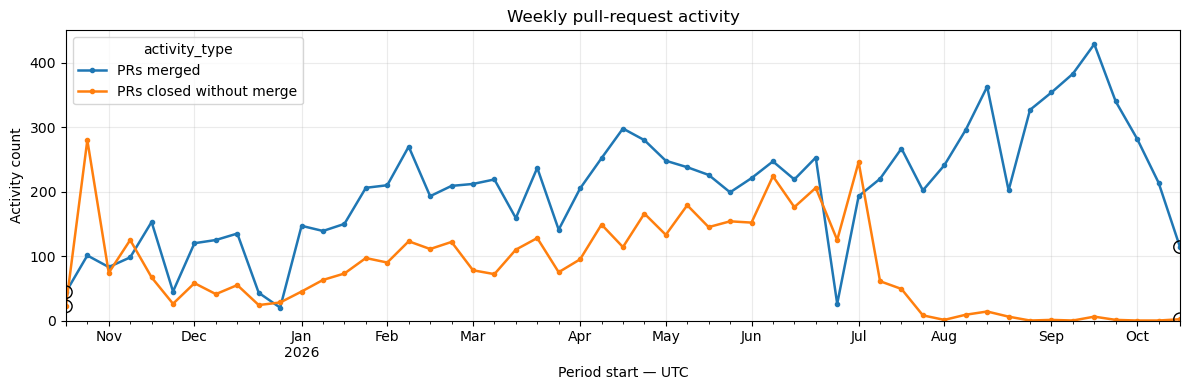

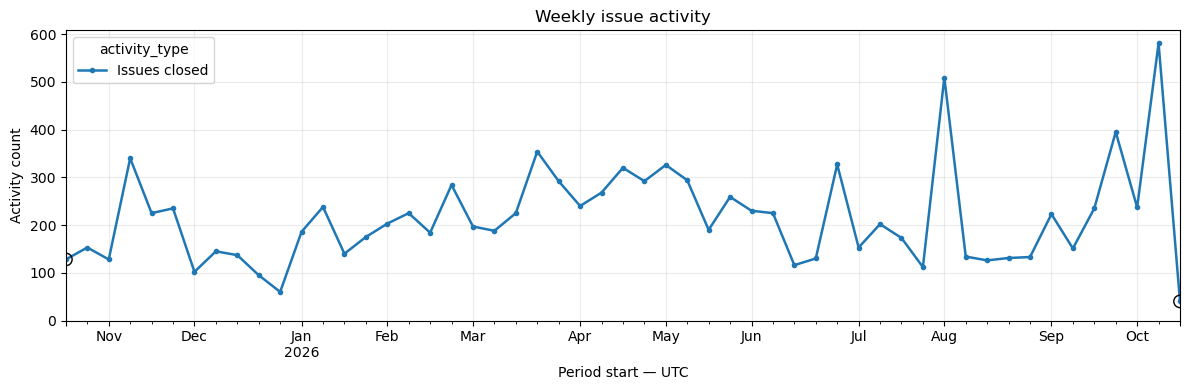

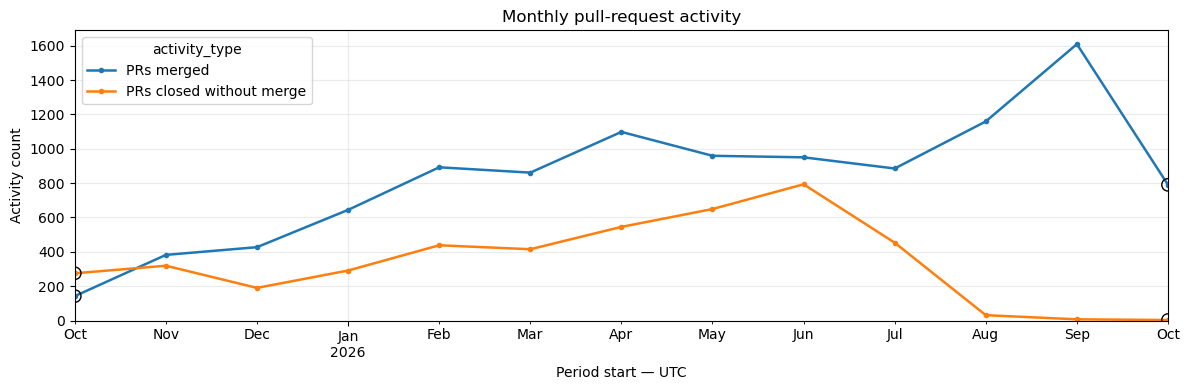

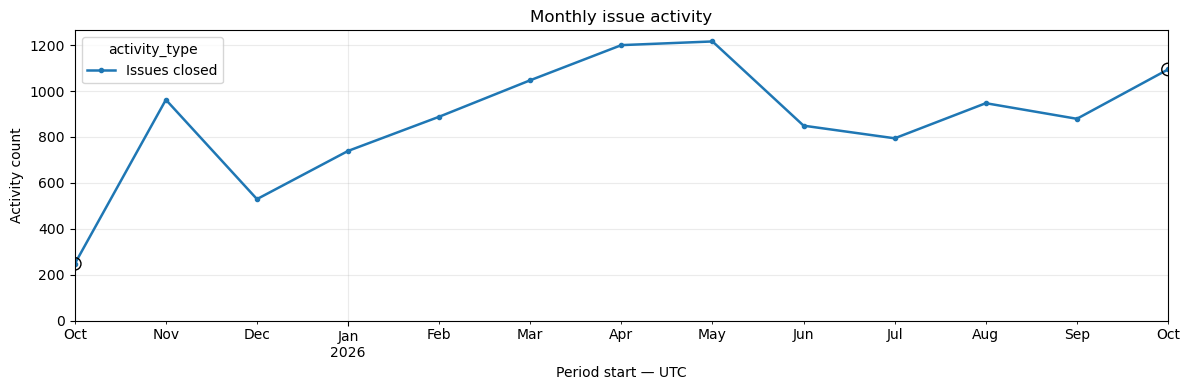

In [6]:
def plot_counts(counts, partial, metrics, title):
    available = [metric for metric in metrics if metric in counts.columns]

    if not available:
        return

    ax = counts[available].rename(columns=LABELS).plot(
        figsize=(12, 4),
        linewidth=1.8,
        marker="o",
        markersize=3,
    )

    # Highlight values from partially observed calendar periods.
    for metric in available:
        ax.scatter(
            counts.index[partial],
            counts.loc[partial, metric],
            s=80,
            facecolors="none",
            edgecolors="black",
            zorder=5,
        )

    # ax.set_title(title + "\nOutlined points = partial calendar periods")
    ax.set_title(title)
    ax.set_xlabel("Period start — UTC")
    ax.set_ylabel("Activity count")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

for name, counts, partial in [
    ("Weekly", weekly, weekly_partial),
    ("Monthly", monthly, monthly_partial),
]:
    plot_counts(
        counts,
        partial,
        ["opened_prs", "merged_prs", "closed_without_merge_prs"],
        f"{name} pull-request activity",
    )

    plot_counts(
        counts,
        partial,
        ["opened_issues", "closed_issues"],
        f"{name} issue activity",
    )

In [5]:
# Summarize metrics

rows = []

for activity, frame in events.groupby("activity_type"):
    times = frame["event_at"].sort_values()
    gaps = times.diff().dropna().dt.total_seconds() / 3600

    rows.append({
        "activity": LABELS.get(activity, activity),
        "count": len(times),
        "mean_interval_hours": gaps.mean(),
        "median_interval_hours": gaps.median(),
        "active_weeks": int((weekly[activity] > 0).sum()),
        "active_months": int((monthly[activity] > 0).sum()),
        "first_observed": times.iloc[0],
        "latest_observed": times.iloc[-1],
        "days_since_first_at_cutoff":
            (END - times.iloc[0]).total_seconds() / 86400,
        "days_since_latest_at_cutoff":
            (END - times.iloc[-1]).total_seconds() / 86400,
    })

summary = pd.DataFrame(rows).round(2)
display(summary)

,activity,count,mean_interval_hours,median_interval_hours,active_weeks,active_months,first_observed,latest_observed,days_since_first_at_cutoff,days_since_latest_at_cutoff
0,Issues closed,11391,0.77,0.15,53,13,2025-10-22 01:21:45+00:00,2026-10-20 22:27:58+00:00,363.94,0.06
1,PRs closed without merge,4409,1.98,0.07,49,13,2025-10-22 02:53:04+00:00,2026-10-20 04:07:10+00:00,363.88,0.83
2,PRs merged,10798,0.81,0.28,53,13,2025-10-22 02:10:30+00:00,2026-10-20 23:42:34+00:00,363.91,0.01


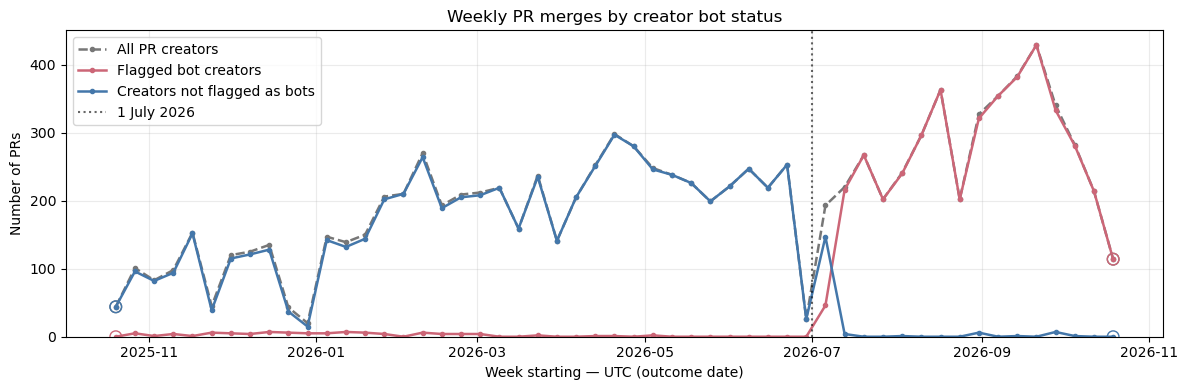

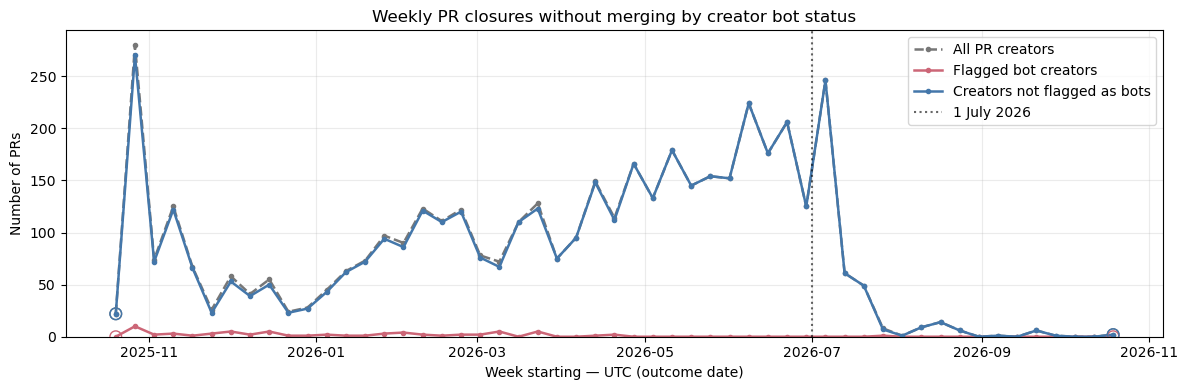

In [11]:
# Compare PR outcomes by the creator's bot status.
# Uses the same observation window as the existing notebook.

pr_outcomes = closures[
    closures["activity_type"].isin(
        ["merged_prs", "closed_without_merge_prs"]
    )
].copy()

pr_outcomes["bot_candidate"] = (
    pr_outcomes["author_type"].fillna("").str.lower().eq("bot")
    | pr_outcomes["author"].fillna("").str.lower().str.endswith("[bot]")
)

all_counts, partial = make_counts(pr_outcomes, "weekly")

bot_counts, _ = make_counts(
    pr_outcomes[pr_outcomes["bot_candidate"]], "weekly"
)

unflagged_counts, _ = make_counts(
    pr_outcomes[~pr_outcomes["bot_candidate"]], "weekly"
)

for metric, title in [
    ("merged_prs", "Weekly PR merges by creator bot status"),
    (
        "closed_without_merge_prs",
        "Weekly PR closures without merging by creator bot status",
    ),
]:
    fig, ax = plt.subplots(figsize=(12, 4))

    for counts, label, color, linestyle in [
        (all_counts, "All PR creators", "#777777", "--"),
        (bot_counts, "Flagged bot creators", "#CC6677", "-"),
        (unflagged_counts, "Creators not flagged as bots", "#4477AA", "-"),
    ]:
        values = counts.reindex(
            index=all_counts.index,
            columns=[metric],
            fill_value=0,
        )[metric]

        ax.plot(
            values.index,
            values,
            label=label,
            color=color,
            linestyle=linestyle,
            marker="o",
            markersize=3,
            linewidth=1.8,
        )

        # Outline partially observed boundary weeks.
        ax.scatter(
            values.index[partial],
            values.loc[partial],
            s=70,
            facecolors="none",
            edgecolors=color,
            zorder=5,
        )

    ax.axvline(
        pd.Timestamp("2026-07-1"),
        color="black",
        linestyle=":",
        alpha=0.6,
        label="1 July 2026",
    )

    ax.set(
        title=title,
        xlabel="Week starting — UTC (outcome date)",
        ylabel="Number of PRs",
    )
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()